Compare SVM, k-NN, and Decision Tree models by manually computing and visualizing performance metrics such as accuracy, precision, recall, and decision boundaries, ensuring a deep analysis of model trade-offs and real-world applicability.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time

df = pd.read_csv("heart_disease_train.csv")

features = ["age", "trestbps", "chol", "thalach", "oldpeak"]
target = "target"

df = df[features + [target]].dropna()

X = df[features].astype(float).to_numpy()
y = df[target].astype(int).to_numpy()

print("Dataset shape:", df.shape)
print("Target classes:", np.unique(y))
print(df.head())


Dataset shape: (79, 6)
Target classes: [0 1]
   age  trestbps  chol  thalach  oldpeak  target
0   77       193   393      184      5.3       1
1   59       138   240       81      5.9       1
2   60       110   463      113      3.3       1
3   29       182   430       79      1.8       1
4   29       200   272      161      3.9       1


In [2]:
np.random.seed(42)

indices = np.random.permutation(len(X))
split = int(0.8 * len(X))

train_idx = indices[:split]
test_idx = indices[split:]

X_train_raw = X[train_idx]
X_test_raw = X[test_idx]
y_train = y[train_idx]
y_test = y[test_idx]

mean = X_train_raw.mean(axis=0)
std = X_train_raw.std(axis=0)
std[std == 0] = 1

X_train = (X_train_raw - mean) / std
X_test = (X_test_raw - mean) / std

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 63
Testing records: 16


In [3]:
def train_svm(X, y, learning_rate=0.001, C=1.0, epochs=1500):
    y_signed = np.where(y == 1, 1, -1)
    weights = np.zeros(X.shape[1])
    bias = 0.0

    for _ in range(epochs):
        margins = y_signed * (X @ weights + bias)
        active = margins < 1

        dw = weights.copy()
        db = 0.0

        if np.any(active):
            dw -= C * (X[active].T @ y_signed[active]) / len(y_signed)
            db = -C * np.sum(y_signed[active]) / len(y_signed)

        weights -= learning_rate * dw
        bias -= learning_rate * db

    return weights, bias


def predict_svm(X, model):
    weights, bias = model
    return ((X @ weights + bias) >= 0).astype(int)

In [4]:
def predict_knn(X_train, y_train, X_test, k=5):
    predictions = []

    train_sq = np.sum(X_train ** 2, axis=1)

    for row in X_test:
        distances = np.maximum(
            np.sum(row ** 2) + train_sq - 2 * (X_train @ row),
            0
        )

        nearest = np.argpartition(distances, k - 1)[:k]
        labels = y_train[nearest]
        classes, counts = np.unique(labels, return_counts=True)
        tied = classes[counts == counts.max()]

        if len(tied) == 1:
            prediction = tied[0]
        else:
            total_distances = [
                distances[nearest][labels == label].sum()
                for label in tied
            ]
            prediction = tied[np.argmin(total_distances)]

        predictions.append(prediction)

    return np.array(predictions)

In [5]:
def gini(y):
    if len(y) == 0:
        return 0

    _, counts = np.unique(y, return_counts=True)
    probabilities = counts / len(y)

    return 1 - np.sum(probabilities ** 2)


def build_tree(X, y, depth=0, max_depth=4, min_samples=5):
    classes, counts = np.unique(y, return_counts=True)
    majority = classes[np.argmax(counts)]

    if len(classes) == 1 or depth >= max_depth or len(y) < min_samples * 2:
        return {"leaf": True, "value": int(majority)}

    best_gain = 0
    best_feature = None
    best_threshold = None

    parent_impurity = gini(y)

    for j in range(X.shape[1]):
        thresholds = np.unique(X[:, j])

        if len(thresholds) > 20:
            thresholds = np.percentile(X[:, j], np.linspace(10, 90, 9))

        for threshold in thresholds:
            left = X[:, j] <= threshold
            right = ~left

            if left.sum() < min_samples or right.sum() < min_samples:
                continue

            gain = parent_impurity
            gain -= left.sum() / len(y) * gini(y[left])
            gain -= right.sum() / len(y) * gini(y[right])

            if gain > best_gain:
                best_gain = gain
                best_feature = j
                best_threshold = threshold

    if best_feature is None:
        return {"leaf": True, "value": int(majority)}

    left = X[:, best_feature] <= best_threshold

    return {
        "leaf": False,
        "feature": best_feature,
        "threshold": best_threshold,
        "left": build_tree(X[left], y[left], depth + 1, max_depth, min_samples),
        "right": build_tree(X[~left], y[~left], depth + 1, max_depth, min_samples)
    }


def predict_tree_one(tree, row):
    if tree["leaf"]:
        return tree["value"]

    if row[tree["feature"]] <= tree["threshold"]:
        return predict_tree_one(tree["left"], row)

    return predict_tree_one(tree["right"], row)


def predict_tree(tree, X):
    return np.array([predict_tree_one(tree, row) for row in X])

In [6]:
models = {}
predictions = {}
times = {}

start = time.time()
models["SVM"] = train_svm(X_train, y_train)
predictions["SVM"] = predict_svm(X_test, models["SVM"])
times["SVM"] = time.time() - start

start = time.time()
predictions["k-NN"] = predict_knn(X_train, y_train, X_test, k=5)
times["k-NN"] = time.time() - start

start = time.time()
models["Decision Tree"] = build_tree(
    X_train, y_train, max_depth=4
)
predictions["Decision Tree"] = predict_tree(
    models["Decision Tree"], X_test
)
times["Decision Tree"] = time.time() - start

print("All three models trained and tested.")

All three models trained and tested.


In [7]:
results = []

for name, pred in predictions.items():
    tp = np.sum((y_test == 1) & (pred == 1))
    tn = np.sum((y_test == 0) & (pred == 0))
    fp = np.sum((y_test == 0) & (pred == 1))
    fn = np.sum((y_test == 1) & (pred == 0))

    accuracy = (tp + tn) / len(y_test)
    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    results.append({
        "Model": name,
        "Accuracy (%)": accuracy * 100,
        "Precision (%)": precision * 100,
        "Recall (%)": recall * 100,
        "F1-Score (%)": f1 * 100,
        "Prediction Time (s)": times[name]
    })

results_df = pd.DataFrame(results)

print(results_df.round(2).to_string(index=False))

        Model  Accuracy (%)  Precision (%)  Recall (%)  F1-Score (%)  Prediction Time (s)
          SVM         81.25          81.25      100.00         89.66                 0.33
         k-NN         81.25          81.25      100.00         89.66                 0.00
Decision Tree         81.25          91.67       84.62         88.00                 0.05


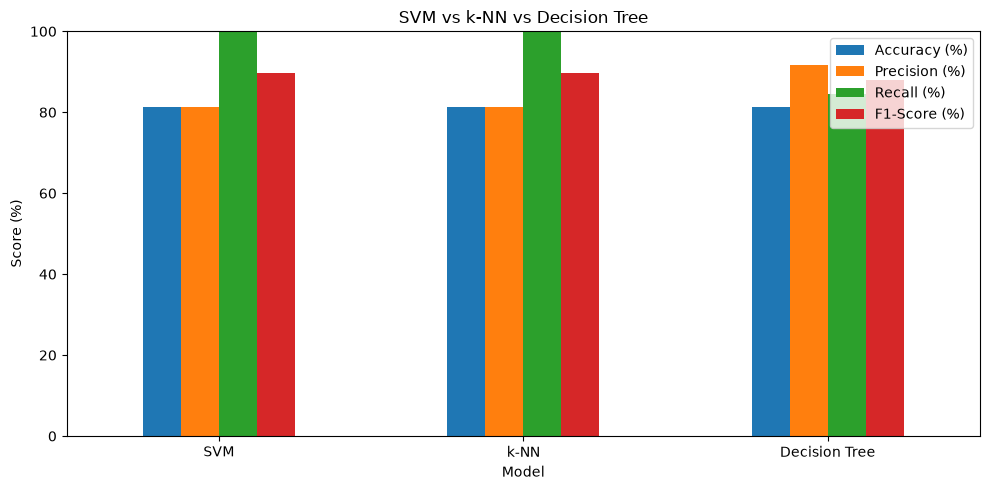

In [8]:
metric_names = [
    "Accuracy (%)",
    "Precision (%)",
    "Recall (%)",
    "F1-Score (%)"
]

plot_df = results_df.set_index("Model")[metric_names]

plot_df.plot(kind="bar", figsize=(10, 5))
plt.title("SVM vs k-NN vs Decision Tree")
plt.ylabel("Score (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

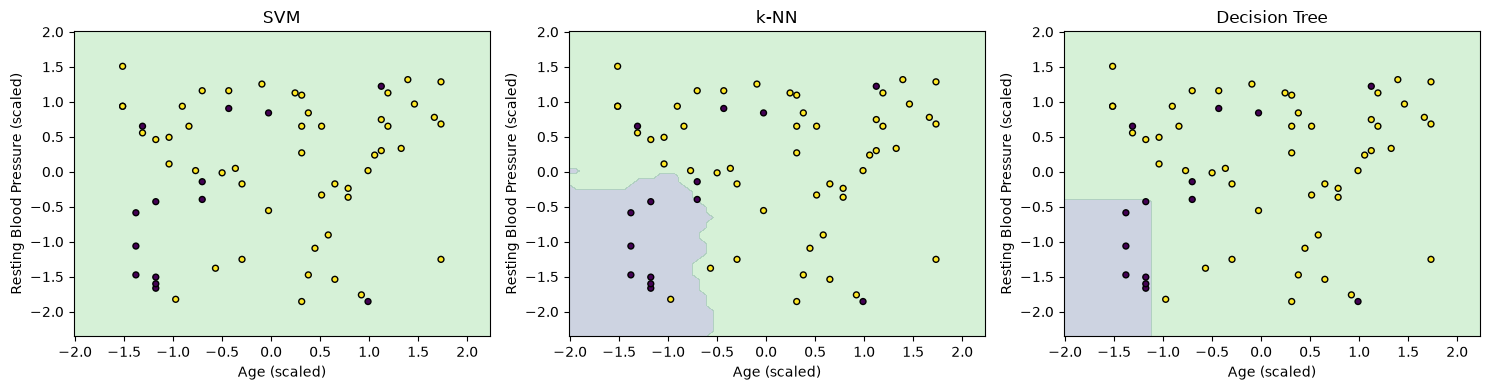

In [9]:
boundary_features = ["age", "trestbps"]
X2 = df[boundary_features].astype(float).to_numpy()
y2 = df[target].astype(int).to_numpy()

X2_train_raw = X2[train_idx]
y2_train = y[train_idx]

mean2 = X2_train_raw.mean(axis=0)
std2 = X2_train_raw.std(axis=0)
std2[std2 == 0] = 1

X2_train = (X2_train_raw - mean2) / std2

x_min, x_max = X2_train[:, 0].min() - 0.5, X2_train[:, 0].max() + 0.5
y_min, y_max = X2_train[:, 1].min() - 0.5, X2_train[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 60),
    np.linspace(y_min, y_max, 60)
)

grid = np.c_[xx.ravel(), yy.ravel()]

svm2 = train_svm(X2_train, y2_train)
tree2 = build_tree(X2_train, y2_train, max_depth=4)

boundary_predictions = {
    "SVM": predict_svm(grid, svm2),
    "k-NN": predict_knn(X2_train, y2_train, grid, k=5),
    "Decision Tree": predict_tree(tree2, grid)
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, pred) in zip(axes, boundary_predictions.items()):
    ax.contourf(
        xx, yy, pred.reshape(xx.shape),
        alpha=0.25, levels=[-0.5, 0.5, 1.5]
    )
    ax.scatter(
        X2_train[:, 0], X2_train[:, 1],
        c=y2_train, edgecolors="black", s=18
    )
    ax.set_title(name)
    ax.set_xlabel("Age (scaled)")
    ax.set_ylabel("Resting Blood Pressure (scaled)")

plt.tight_layout()
plt.show()

In [10]:
best_accuracy = results_df.loc[
    results_df["Accuracy (%)"].idxmax(), "Model"
]

best_recall = results_df.loc[
    results_df["Recall (%)"].idxmax(), "Model"
]

best_f1 = results_df.loc[
    results_df["F1-Score (%)"].idxmax(), "Model"
]

fastest = results_df.loc[
    results_df["Prediction Time (s)"].idxmin(), "Model"
]

print("Model Comparison")
print("----------------")
print("Highest accuracy:", best_accuracy)
print("Highest recall:", best_recall)
print("Highest F1-score:", best_f1)
print("Fastest prediction:", fastest)

print("\nTrade-off Analysis")
print("SVM: learns a linear boundary and can generalize well with suitable scaling.")
print("k-NN: simple and flexible, but prediction can be slow on large datasets.")
print("Decision Tree: easy to interpret, but can overfit without depth limits.")

print("\nConclusion")
print("All three models were evaluated using the same test set.")
print("Accuracy, precision, recall, F1-score, prediction time, and")
print("two-feature decision boundaries were compared.")
print("The best model should be selected based on the application requirements.")

Model Comparison
----------------
Highest accuracy: SVM
Highest recall: SVM
Highest F1-score: SVM
Fastest prediction: k-NN

Trade-off Analysis
SVM: learns a linear boundary and can generalize well with suitable scaling.
k-NN: simple and flexible, but prediction can be slow on large datasets.
Decision Tree: easy to interpret, but can overfit without depth limits.

Conclusion
All three models were evaluated using the same test set.
Accuracy, precision, recall, F1-score, prediction time, and
two-feature decision boundaries were compared.
The best model should be selected based on the application requirements.
